# Vanilla Transformer architecture

In [ ]:
# Cell 1: Imports and reproducibility

import torch
import torch.nn as nn
import torch.nn.functional as F
import random
import numpy as np

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )

PyTorch: 2.11.0+cu128
Device: cuda
GPU: Tesla T4
VRAM: 14.56 GB


In [ ]:
# Cell 2: Matched vanilla Transformer baseline

class VanillaTransformer(nn.Module):
    def __init__(
        self,
        vocab_size=2,
        d_model=32,
        n_heads=4,
        ff_dim=184,
        num_layers=2,
        max_seq_len=512,
        num_classes=2
    ):
        super().__init__()

        self.d_model = d_model
        self.max_seq_len = max_seq_len

        # Same token embedding setup as RLT V4
        self.token_embedding = nn.Embedding(
            vocab_size, d_model
        )

        # Standard Transformer encoder block
        # No positional embeddings
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=ff_dim,
            dropout=0.0,
            activation="gelu",
            batch_first=True,
            norm_first=False
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        # Same output dimension as RLT
        self.output_head = nn.Linear(
            d_model, num_classes
        )

    def forward(self, input_ids):

        B, T = input_ids.shape

        assert T <= self.max_seq_len

        # Token embeddings only — NO positional embedding
        x = self.token_embedding(input_ids)

        # Causal mask
        causal_mask = torch.triu(
            torch.ones(
                T, T,
                device=input_ids.device,
                dtype=torch.bool
            ),
            diagonal=1
        )

        # Vanilla Transformer
        x = self.transformer(
            x,
            mask=causal_mask
        )

        # Per-token classification
        logits = self.output_head(x)

        return logits

In [ ]:
# Cell 3: Instantiate baseline and inspect parameter count

baseline = VanillaTransformer(
    vocab_size=2,
    d_model=32,
    n_heads=4,
    ff_dim=184,
    num_layers=2,
    max_seq_len=512,
    num_classes=2
).to(device)

total_params = sum(
    p.numel() for p in baseline.parameters()
)

print("Total parameters:", total_params)
print("Target RLT V4 parameters: 32,802")
print("Difference:", total_params - 32802)

Total parameters: 32818
Target RLT V4 parameters: 32,802
Difference: 16


In [ ]:
# Cell 4: Test forward pass

test_x = torch.randint(
    0, 2,
    (4, 16),
    device=device
)

with torch.no_grad():
    test_logits = baseline(test_x)

print("Input shape :", test_x.shape)
print("Logits shape:", test_logits.shape)
print("Finite:", torch.isfinite(test_logits).all().item())

Input shape : torch.Size([4, 16])
Logits shape: torch.Size([4, 16, 2])
Finite: True


In [ ]:
# Cell 5: Running parity training data



def make_running_parity_data(N, T, device):
    X = torch.randint(
        0, 2,
        (N, T),
        device=device
    )

    # Running number of 1s, modulo 2
    Y = X.cumsum(dim=1) % 2

    return X, Y
N = 8000
T = 16

X_train, y_train = make_running_parity_data(
    N, T, device
)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nExample input :", X_train[0].tolist())
print("Example target:", y_train[0].tolist())

X_train: torch.Size([8000, 16])
y_train: torch.Size([8000, 16])

Example input : [1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0]
Example target: [1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1]


In [ ]:
# Cell 6: Train vanilla Transformer

optimizer = torch.optim.AdamW(
    baseline.parameters(),
    lr=3e-4,
    weight_decay=1e-2
)

batch_size = 64
steps = 1000

baseline.train()

for step in range(steps):

    # Random mini-batch
    idx = torch.randint(
        0,
        N,
        (batch_size,),
        device=device
    )

    xb = X_train[idx]
    yb = y_train[idx]

    # Forward
    logits = baseline(xb)

    # Per-token cross entropy
    loss = F.cross_entropy(
        logits.reshape(-1, 2),
        yb.reshape(-1)
    )

    # Backpropagation
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if step % 100 == 0:
        with torch.no_grad():
            predictions = logits.argmax(dim=-1)
            accuracy = (
                predictions == yb
            ).float().mean().item() * 100

        print(
            f"Step {step:4d} | "
            f"Loss {loss.item():.4f} | "
            f"Accuracy {accuracy:.2f}%"
        )

Step    0 | Loss 0.7020 | Accuracy 52.54%
Step  100 | Loss 0.6401 | Accuracy 56.64%
Step  200 | Loss 0.6279 | Accuracy 57.42%
Step  300 | Loss 0.6269 | Accuracy 59.18%
Step  400 | Loss 0.6280 | Accuracy 59.47%
Step  500 | Loss 0.6302 | Accuracy 56.15%
Step  600 | Loss 0.6312 | Accuracy 58.20%
Step  700 | Loss 0.6512 | Accuracy 53.91%
Step  800 | Loss 0.6145 | Accuracy 58.89%
Step  900 | Loss 0.6071 | Accuracy 57.81%


In [ ]:
# Cell 7: Fresh evaluation datasets

X_16, y_16 = make_running_parity_data(2000, 16, device)
X_32, y_32 = make_running_parity_data(2000, 32, device)
X_64, y_64 = make_running_parity_data(2000, 64, device)
X_128, y_128 = make_running_parity_data(1000, 128, device)
X_256, y_256 = make_running_parity_data(1000, 256, device)
X_512, y_512 = make_running_parity_data(500, 512, device)

print("Test datasets created.")

Test datasets created.


In [ ]:
# Cell 8: Evaluate vanilla Transformer

def evaluate_model(model, X, Y, batch_size=128):
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for start in range(0, len(X), batch_size):
            xb = X[start:start + batch_size]
            yb = Y[start:start + batch_size]

            logits = model(xb)
            predictions = logits.argmax(dim=-1)

            correct += (predictions == yb).sum().item()
            total += yb.numel()

    return 100.0 * correct / total


lengths = [16, 32, 64, 128, 256, 512]
datasets = [
    (X_16, y_16),
    (X_32, y_32),
    (X_64, y_64),
    (X_128, y_128),
    (X_256, y_256),
    (X_512, y_512),
]

print("Vanilla Transformer evaluation")
print("-" * 40)

for length, (X, Y) in zip(lengths, datasets):
    acc = evaluate_model(baseline, X, Y)

    print(
        f"Length {length:3d} → {acc:.2f}%"
    )

Vanilla Transformer evaluation
----------------------------------------
Length  16 → 61.44%
Length  32 → 55.78%
Length  64 → 52.92%
Length 128 → 51.36%
Length 256 → 50.61%
Length 512 → 50.43%


In [ ]:
# Cell 9: Reproducibility + common experiment settings

SEEDS = [42, 123, 456]

TRAIN_N = 8000
TRAIN_LEN = 16

BATCH_SIZE = 64
TRAIN_STEPS = 1000
LR = 3e-4
WEIGHT_DECAY = 1e-2

EVAL_LENGTHS = [16, 32, 64, 128, 256, 512]


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def make_fixed_dataset(seed, N, T):
    # Separate generator so dataset generation is reproducible
    generator = torch.Generator(device=device)
    generator.manual_seed(seed)

    X = torch.randint(
        0, 2,
        (N, T),
        generator=generator,
        device=device
    )

    Y = X.cumsum(dim=1) % 2

    return X, Y

In [ ]:
# Cell 10: Create reproducible datasets for each seed

datasets_by_seed = {}

for seed in SEEDS:

    train_X, train_Y = make_fixed_dataset(
        seed,
        TRAIN_N,
        TRAIN_LEN
    )

    test_sets = {}

    for length in EVAL_LENGTHS:
        N = 2000 if length <= 64 else 1000

        if length == 512:
            N = 500

        test_X, test_Y = make_fixed_dataset(
            seed + 1000,
            N,
            length
        )

        test_sets[length] = (test_X, test_Y)

    datasets_by_seed[seed] = {
        "train": (train_X, train_Y),
        "test": test_sets
    }

print("Datasets created for seeds:", SEEDS)

for seed in SEEDS:
    X, Y = datasets_by_seed[seed]["train"]
    print(
        f"Seed {seed}: "
        f"train X={X.shape}, Y={Y.shape}"
    )

Datasets created for seeds: [42, 123, 456]
Seed 42: train X=torch.Size([8000, 16]), Y=torch.Size([8000, 16])
Seed 123: train X=torch.Size([8000, 16]), Y=torch.Size([8000, 16])
Seed 456: train X=torch.Size([8000, 16]), Y=torch.Size([8000, 16])


In [ ]:
# Cell 11: Common training function

def train_model(model, X_train, y_train, seed):
    set_seed(seed)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LR,
        weight_decay=WEIGHT_DECAY
    )

    model.train()

    N = len(X_train)

    for step in range(TRAIN_STEPS):

        idx = torch.randint(
            0,
            N,
            (BATCH_SIZE,),
            device=device
        )

        xb = X_train[idx]
        yb = y_train[idx]

        logits = model(xb)

        loss = F.cross_entropy(
            logits.reshape(-1, 2),
            yb.reshape(-1)
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if step % 200 == 0 or step == TRAIN_STEPS - 1:
            with torch.no_grad():
                pred = logits.argmax(dim=-1)
                acc = (
                    (pred == yb)
                    .float()
                    .mean()
                    .item() * 100
                )

            print(
                f"Step {step:4d} | "
                f"Loss {loss.item():.4f} | "
                f"Batch Acc {acc:.2f}%"
            )

    return model

In [ ]:
#12
def create_vanilla(seed):
    set_seed(seed)

    model = VanillaTransformer(
        vocab_size=2,
        d_model=32,
        n_heads=4,
        ff_dim=184,
        num_layers=2,
        max_seq_len=512,
        num_classes=2
    ).to(device)

    # Give each Transformer layer an independent initialization
    for layer in model.transformer.layers:
        for name, param in layer.named_parameters():
            if param.dim() > 1:
                nn.init.xavier_uniform_(param)
            else:
                nn.init.zeros_(param)

        # LayerNorm scale should start at 1
        nn.init.ones_(layer.norm1.weight)
        nn.init.ones_(layer.norm2.weight)

    return model


def train_model(model, X_train, y_train, seed):
    set_seed(seed)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LR,
        weight_decay=WEIGHT_DECAY
    )

    model.train()
    N = len(X_train)

    for step in range(TRAIN_STEPS):

        idx = torch.randint(
            0,
            N,
            (BATCH_SIZE,),
            device=device
        )

        xb = X_train[idx]
        yb = y_train[idx]

        logits = model(xb)

        loss = F.cross_entropy(
            logits.reshape(-1, 2),
            yb.reshape(-1)
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if step % 200 == 0 or step == TRAIN_STEPS - 1:
            with torch.no_grad():
                pred = logits.argmax(dim=-1)
                acc = (pred == yb).float().mean().item() * 100

            print(
                f"Step {step:4d} | "
                f"Loss {loss.item():.4f} | "
                f"Batch Acc {acc:.2f}%"
            )

    return model

In [ ]:
print(datasets_by_seed[42].keys())

dict_keys(['train', 'test'])


In [ ]:
print(type(datasets_by_seed[42]["train"]))
print(type(datasets_by_seed[42]["test"]))

print("Train:")
print([x.shape for x in datasets_by_seed[42]["train"]])

print("Test lengths:")
for length, data in datasets_by_seed[42]["test"].items():
    print(length, [x.shape for x in data])

<class 'tuple'>
<class 'dict'>
Train:
[torch.Size([8000, 16]), torch.Size([8000, 16])]
Test lengths:
16 [torch.Size([2000, 16]), torch.Size([2000, 16])]
32 [torch.Size([2000, 32]), torch.Size([2000, 32])]
64 [torch.Size([2000, 64]), torch.Size([2000, 64])]
128 [torch.Size([1000, 128]), torch.Size([1000, 128])]
256 [torch.Size([1000, 256]), torch.Size([1000, 256])]
512 [torch.Size([500, 512]), torch.Size([500, 512])]


In [ ]:
seed = 42

X_train, Y_train = datasets_by_seed[seed]["train"]

model_vanilla_42 = create_vanilla(seed)

print(
    "Parameters:",
    sum(p.numel() for p in model_vanilla_42.parameters())
)

model_vanilla_42 = train_model(
    model_vanilla_42,
    X_train,
    Y_train,
    seed
)

Parameters: 32818
Step    0 | Loss 0.7209 | Batch Acc 47.17%
Step  200 | Loss 0.6225 | Batch Acc 58.30%
Step  400 | Loss 0.6238 | Batch Acc 56.54%
Step  600 | Loss 0.5983 | Batch Acc 59.38%
Step  800 | Loss 0.5671 | Batch Acc 59.86%
Step  999 | Loss 0.5663 | Batch Acc 59.86%


In [ ]:
@torch.no_grad()
def evaluate_model(model, X, Y):
    model.eval()

    logits = model(X)
    pred = logits.argmax(dim=-1)

    accuracy = (pred == Y).float().mean().item() * 100

    return accuracy


print("Vanilla Transformer evaluation")
print("----------------------------------------")

vanilla_results_42 = {}

for length in EVAL_LENGTHS:
    X_test, Y_test = datasets_by_seed[42]["test"][length]

    acc = evaluate_model(
        model_vanilla_42,
        X_test,
        Y_test
    )

    vanilla_results_42[length] = acc

    print(f"Length {length:3d} → {acc:.2f}%")

Vanilla Transformer evaluation
----------------------------------------
Length  16 → 61.71%
Length  32 → 55.43%
Length  64 → 52.85%
Length 128 → 51.31%
Length 256 → 50.81%
Length 512 → 50.53%


In [ ]:
vanilla_models = {
    42: model_vanilla_42
}

vanilla_results = {
    42: vanilla_results_42
}

for seed in [123, 456]:

    print("=" * 60)
    print(f"Training Vanilla Transformer — Seed {seed}")
    print("=" * 60)

    X_train, Y_train = datasets_by_seed[seed]["train"]

    model = create_vanilla(seed)

    print(
        "Parameters:",
        sum(p.numel() for p in model.parameters())
    )

    model = train_model(
        model,
        X_train,
        Y_train,
        seed
    )

    vanilla_models[seed] = model

    results = {}

    print()
    print(f"Evaluation — Seed {seed}")
    print("----------------------------------------")

    for length in EVAL_LENGTHS:

        X_test, Y_test = datasets_by_seed[seed]["test"][length]

        acc = evaluate_model(
            model,
            X_test,
            Y_test
        )

        results[length] = acc

        print(f"Length {length:3d} → {acc:.2f}%")

    vanilla_results[seed] = results

Training Vanilla Transformer — Seed 123
Parameters: 32818
Step    0 | Loss 0.7738 | Batch Acc 55.08%
Step  200 | Loss 0.6208 | Batch Acc 55.37%
Step  400 | Loss 0.6124 | Batch Acc 57.13%
Step  600 | Loss 0.5845 | Batch Acc 60.94%
Step  800 | Loss 0.5447 | Batch Acc 63.09%
Step  999 | Loss 0.5466 | Batch Acc 62.79%

Evaluation — Seed 123
----------------------------------------
Length  16 → 62.28%
Length  32 → 56.03%
Length  64 → 53.05%
Length 128 → 51.43%
Length 256 → 50.71%
Length 512 → 50.45%
Training Vanilla Transformer — Seed 456
Parameters: 32818
Step    0 | Loss 0.7492 | Batch Acc 51.46%
Step  200 | Loss 0.6429 | Batch Acc 57.32%
Step  400 | Loss 0.6182 | Batch Acc 56.45%
Step  600 | Loss 0.5884 | Batch Acc 60.94%
Step  800 | Loss 0.5671 | Batch Acc 60.55%
Step  999 | Loss 0.5549 | Batch Acc 61.43%

Evaluation — Seed 456
----------------------------------------
Length  16 → 61.45%
Length  32 → 55.98%
Length  64 → 52.89%
Length 128 → 51.56%
Length 256 → 50.83%
Length 512 → 50.43%


#RLT Architecture

In [ ]:
# ============================================================
# RLT V4 — Required Components
# ============================================================

import math
import torch
import torch.nn as nn
import torch.nn.functional as F


# ------------------------------------------------------------
# RMSNorm
# ------------------------------------------------------------

class RMSNorm(nn.Module):
    def __init__(self, d_model, eps=1e-8):
        super().__init__()

        self.eps = eps
        self.weight = nn.Parameter(
            torch.ones(d_model)
        )

    def forward(self, x):

        rms = torch.sqrt(
            torch.mean(
                x ** 2,
                dim=-1,
                keepdim=True
            ) + self.eps
        )

        return (x / rms) * self.weight


# ------------------------------------------------------------
# Sliding Window Attention
# ------------------------------------------------------------

class SlidingWindowAttentionV2(nn.Module):

    def __init__(
        self,
        d_model,
        n_heads=4,
        window_size=8
    ):
        super().__init__()

        assert d_model % n_heads == 0

        self.d_model = d_model
        self.n_heads = n_heads
        self.window_size = window_size
        self.head_dim = d_model // n_heads

        self.q_proj = nn.Linear(
            d_model,
            d_model,
            bias=False
        )

        self.k_proj = nn.Linear(
            d_model,
            d_model,
            bias=False
        )

        self.v_proj = nn.Linear(
            d_model,
            d_model,
            bias=False
        )

        self.out_proj = nn.Linear(
            d_model,
            d_model,
            bias=False
        )

        self.norm = RMSNorm(d_model)

    def forward(self, x, cache=None):

        B = x.size(0)

        q = self.q_proj(x)
        k_new = self.k_proj(x)
        v_new = self.v_proj(x)

        if cache is None:
            k = k_new
            v = v_new

        else:
            k_old, v_old = cache

            k = torch.cat(
                [k_old, k_new],
                dim=1
            )

            v = torch.cat(
                [v_old, v_new],
                dim=1
            )

        k = k[:, -self.window_size:, :]
        v = v[:, -self.window_size:, :]

        q = q.view(
            B,
            1,
            self.n_heads,
            self.head_dim
        ).transpose(1, 2)

        k_heads = k.view(
            B,
            -1,
            self.n_heads,
            self.head_dim
        ).transpose(1, 2)

        v_heads = v.view(
            B,
            -1,
            self.n_heads,
            self.head_dim
        ).transpose(1, 2)

        scores = torch.matmul(
            q,
            k_heads.transpose(-2, -1)
        ) / math.sqrt(self.head_dim)

        attention = F.softmax(
            scores,
            dim=-1
        )

        output = torch.matmul(
            attention,
            v_heads
        )

        output = (
            output
            .transpose(1, 2)
            .contiguous()
        )

        output = output.view(
            B,
            1,
            self.d_model
        )

        output = self.out_proj(output)

        output = self.norm(
            x + output
        )

        return output, (k, v)


# ------------------------------------------------------------
# Causal Encoder
# ------------------------------------------------------------

class RLTEncoder(nn.Module):

    def __init__(
        self,
        d_model=32,
        n_heads=4,
        ff_dim=128,
        n_layers=1
    ):
        super().__init__()

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=ff_dim,
            dropout=0.0,
            activation="gelu",
            batch_first=True,
            norm_first=False
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=n_layers
        )

        self.norm = RMSNorm(d_model)

    def forward(self, x):

        T = x.shape[1]

        causal_mask = torch.triu(
            torch.ones(
                T,
                T,
                device=x.device,
                dtype=torch.bool
            ),
            diagonal=1
        )

        e = self.encoder(
            x,
            mask=causal_mask
        )

        return self.norm(e)


# ------------------------------------------------------------
# Gated State Merge
# ------------------------------------------------------------

class RLTGatedMerge(nn.Module):

    def __init__(
        self,
        d_model,
        alpha=0.1
    ):
        super().__init__()

        self.alpha = alpha

        self.state_norm = RMSNorm(
            d_model
        )

        self.gate = nn.Linear(
            2 * d_model,
            d_model
        )

        self.state_proj = nn.Linear(
            d_model,
            d_model,
            bias=False
        )

    def forward(
        self,
        e_t,
        s_prev
    ):

        r_prev = self.state_norm(
            s_prev
        )

        merged_input = torch.cat(
            [e_t, r_prev],
            dim=-1
        )

        g_t = torch.sigmoid(
            self.gate(merged_input)
        )

        feedback = self.state_proj(
            r_prev
        )

        return (
            e_t
            + self.alpha * g_t * feedback
        )


# ------------------------------------------------------------
# Encoder Cross Attention
# ------------------------------------------------------------

class EncoderCrossAttention(nn.Module):

    def __init__(
        self,
        d_model=32,
        n_heads=4
    ):
        super().__init__()

        self.attn = nn.MultiheadAttention(
            embed_dim=d_model,
            num_heads=n_heads,
            batch_first=True,
            dropout=0.0
        )

        self.norm = RMSNorm(d_model)

    def forward(
        self,
        query,
        memory
    ):

        q = self.norm(query)

        output, _ = self.attn(
            q,
            memory,
            memory,
            need_weights=False
        )

        return query + output


# ------------------------------------------------------------
# Feed Forward Network
# ------------------------------------------------------------

class RLTFFN(nn.Module):

    def __init__(
        self,
        d_model=32,
        ff_dim=128
    ):
        super().__init__()

        self.norm = RMSNorm(
            d_model
        )

        self.fc1 = nn.Linear(
            d_model,
            ff_dim
        )

        self.fc2 = nn.Linear(
            ff_dim,
            d_model
        )

    def forward(self, x):

        residual = x

        x = self.norm(x)
        x = self.fc1(x)
        x = F.gelu(x)
        x = self.fc2(x)

        return residual + x


# ------------------------------------------------------------
# RLT Decoder Transition
# ------------------------------------------------------------

class RLTDecoderTransitionV2(nn.Module):

    def __init__(
        self,
        d_model=32,
        n_heads=4,
        ff_dim=128,
        window_size=8
    ):
        super().__init__()

        self.merge = RLTGatedMerge(
            d_model=d_model,
            alpha=0.1
        )

        self.swa = SlidingWindowAttentionV2(
            d_model=d_model,
            window_size=window_size
        )

        self.cross_attn = EncoderCrossAttention(
            d_model=d_model,
            n_heads=n_heads
        )

        self.ffn = RLTFFN(
            d_model=d_model,
            ff_dim=ff_dim
        )

    def forward(
        self,
        e_t,
        s_prev,
        memory,
        cache
    ):

        u_t = self.merge(
            e_t,
            s_prev
        )

        x = u_t.unsqueeze(1)

        x, new_cache = self.swa(
            x,
            cache
        )

        x = self.cross_attn(
            x,
            memory
        )

        x = self.ffn(x)

        s_t = x.squeeze(1)

        return s_t, new_cache

In [ ]:
# Cell: RLTModelV4 — remove absolute positional embeddings

class RLTModelV4(nn.Module):
    def __init__(
        self,
        vocab_size,
        d_model=32,
        n_heads=4,
        ff_dim=128,
        window_size=8,
        max_seq_len=128,
        num_classes=None
    ):
        super().__init__()

        if num_classes is None:
            num_classes = vocab_size

        self.d_model = d_model
        self.max_seq_len = max_seq_len

        # No positional embedding
        self.token_embedding = nn.Embedding(vocab_size, d_model)

        self.encoder = RLTEncoder(
            d_model=d_model,
            n_heads=n_heads,
            ff_dim=ff_dim
        )

        self.transition = RLTDecoderTransitionV2(
            d_model=d_model,
            n_heads=n_heads,
            ff_dim=ff_dim,
            window_size=window_size
        )

        self.output_norm = RMSNorm(d_model)
        self.output_head = nn.Linear(d_model, num_classes)

    def forward(self, input_ids):

        B, T = input_ids.shape

        assert T <= self.max_seq_len

        # Token embedding only
        x = self.token_embedding(input_ids)

        memory = self.encoder(x)

        s_prev = torch.zeros(
            B,
            self.d_model,
            device=input_ids.device,
            dtype=x.dtype
        )

        cache = None
        states = []

        for t in range(T):

            e_t = memory[:, t, :]
            memory_prefix = memory[:, :t+1, :]

            s_t, cache = self.transition(
                e_t,
                s_prev,
                memory_prefix,
                cache
            )

            states.append(s_t)
            s_prev = s_t

        states = torch.stack(states, dim=1)

        normalized_states = self.output_norm(states)

        logits = self.output_head(normalized_states)

        return logits, states


model_run_v4 = RLTModelV4(
    vocab_size=2,
    d_model=32,
    n_heads=4,
    ff_dim=128,
    window_size=8,
    max_seq_len=128,
    num_classes=2
).to(device)

print("Parameters:", sum(p.numel() for p in model_run_v4.parameters()))

Parameters: 32802


In [ ]:
print("RLTModelV4:", RLTModelV4)

RLTModelV4: <class '__main__.RLTModelV4'>


In [ ]:
print([name for name in globals() if "RLT" in name.upper()])

['RLTModelV4', 'RLTEncoder', 'RLTGatedMerge', 'RLTFFN', 'RLTDecoderTransitionV2']


In [ ]:
# ============================================================
# RLT V4 — Parameter Check
# ============================================================

model_check = RLTModelV4(
    vocab_size=2,
    d_model=32,
    n_heads=4,
    ff_dim=128,
    window_size=8,
    max_seq_len=512,
    num_classes=2
).to(device)

rlt_params = sum(
    p.numel()
    for p in model_check.parameters()
)

print(f"RLT V4 parameters: {rlt_params:,}")

RLT V4 parameters: 32,802


In [ ]:
# RLT forward-pass sanity check

model_check = RLTModelV4(
    vocab_size=2,
    d_model=32,
    n_heads=4,
    ff_dim=128,
    window_size=8,
    max_seq_len=512,
    num_classes=2
).to(device)

X_check = torch.randint(0, 2, (4, 16), device=device)

with torch.no_grad():
    logits, state = model_check(X_check)

print("Input shape :", X_check.shape)
print("Logits shape:", logits.shape)
print("State shape :", state.shape)
print("Parameters  :", sum(p.numel() for p in model_check.parameters()))

Input shape : torch.Size([4, 16])
Logits shape: torch.Size([4, 16, 2])
State shape : torch.Size([4, 16, 32])
Parameters  : 32802


In [ ]:
def create_rlt(seed):
    set_seed(seed)

    model = RLTModelV4(
        vocab_size=2,
        d_model=32,
        n_heads=4,
        ff_dim=128,
        window_size=8,
        max_seq_len=512,
        num_classes=2
    ).to(device)

    return model


def train_rlt(model, X_train, y_train, seed):
    set_seed(seed)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LR,
        weight_decay=WEIGHT_DECAY
    )

    model.train()
    N = len(X_train)

    history = {
        "step": [],
        "loss": [],
        "accuracy": []
    }

    for step in range(TRAIN_STEPS):

        idx = torch.randint(
            0, N,
            (BATCH_SIZE,),
            device=device
        )

        xb = X_train[idx]
        yb = y_train[idx]

        logits, _ = model(xb)

        loss = F.cross_entropy(
            logits.reshape(-1, 2),
            yb.reshape(-1)
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if step % 200 == 0 or step == TRAIN_STEPS - 1:

            pred = logits.argmax(dim=-1)
            acc = (pred == yb).float().mean().item() * 100

            history["step"].append(step)
            history["loss"].append(loss.item())
            history["accuracy"].append(acc)

            print(
                f"Step {step:4d} | "
                f"Loss {loss.item():.4f} | "
                f"Accuracy {acc:.2f}%"
            )

    return model, history


@torch.no_grad()
def evaluate_rlt(model, X, Y):
    model.eval()

    logits, _ = model(X)

    pred = logits.argmax(dim=-1)

    return (
        (pred == Y)
        .float()
        .mean()
        .item()
        * 100
    )

In [ ]:
seed = 42

X_train, Y_train = datasets_by_seed[seed]["train"]

rlt_model_42 = create_rlt(seed)

print(
    "RLT parameters:",
    sum(p.numel() for p in rlt_model_42.parameters())
)

rlt_model_42, rlt_history_42 = train_rlt(
    rlt_model_42,
    X_train,
    Y_train,
    seed
)

RLT parameters: 32802
Step    0 | Loss 0.8120 | Accuracy 47.17%
Step  200 | Loss 0.6126 | Accuracy 60.74%
Step  400 | Loss 0.0090 | Accuracy 100.00%
Step  600 | Loss 0.3186 | Accuracy 83.50%
Step  800 | Loss 0.0060 | Accuracy 100.00%
Step  999 | Loss 0.0031 | Accuracy 100.00%


In [ ]:
rlt_results_42 = {}

X_train, Y_train = datasets_by_seed[42]["train"]

for length in EVAL_LENGTHS:
    X_test, Y_test = datasets_by_seed[42]["test"][length]

    acc = evaluate_rlt(
        rlt_model_42,
        X_test,
        Y_test
    )

    rlt_results_42[length] = acc

    print(f"Length {length:3d} → {acc:.2f}%")

Length  16 → 99.97%
Length  32 → 99.86%
Length  64 → 99.64%
Length 128 → 99.43%
Length 256 → 98.68%
Length 512 → 97.15%


In [ ]:
rlt_results = {
    42: rlt_results_42
}

rlt_histories = {
    42: rlt_history_42
}

rlt_models = {
    42: rlt_model_42
}

for seed in [123, 456]:

    print("\n" + "=" * 50)
    print(f"RLT SEED {seed}")
    print("=" * 50)

    X_train, Y_train = datasets_by_seed[seed]["train"]

    model = create_rlt(seed)

    model, history = train_rlt(
        model,
        X_train,
        Y_train,
        seed
    )

    results = {}

    for length in EVAL_LENGTHS:

        X_test, Y_test = datasets_by_seed[seed]["test"][length]

        acc = evaluate_rlt(
            model,
            X_test,
            Y_test
        )

        results[length] = acc

        print(f"Length {length:3d} → {acc:.2f}%")

    rlt_results[seed] = results
    rlt_histories[seed] = history
    rlt_models[seed] = model


RLT SEED 123
Step    0 | Loss 0.7620 | Accuracy 46.09%
Step  200 | Loss 0.6081 | Accuracy 57.52%
Step  400 | Loss 0.1522 | Accuracy 96.00%
Step  600 | Loss 0.0032 | Accuracy 100.00%
Step  800 | Loss 0.0017 | Accuracy 100.00%
Step  999 | Loss 0.0300 | Accuracy 99.41%
Length  16 → 99.96%
Length  32 → 99.88%
Length  64 → 99.70%
Length 128 → 99.25%
Length 256 → 97.94%
Length 512 → 96.07%

RLT SEED 456
Step    0 | Loss 0.7879 | Accuracy 51.46%
Step  200 | Loss 0.6291 | Accuracy 58.69%
Step  400 | Loss 0.0171 | Accuracy 99.71%
Step  600 | Loss 0.0028 | Accuracy 100.00%
Step  800 | Loss 0.0013 | Accuracy 100.00%
Step  999 | Loss 0.0008 | Accuracy 100.00%
Length  16 → 100.00%
Length  32 → 99.97%
Length  64 → 99.94%
Length 128 → 99.75%
Length 256 → 99.09%
Length 512 → 98.65%


#Visualise

In [ ]:
import numpy as np

rlt_mean = {}
rlt_std = {}

for length in EVAL_LENGTHS:
    values = [
        rlt_results[42][length],
        rlt_results[123][length],
        rlt_results[456][length]
    ]

    rlt_mean[length] = np.mean(values)
    rlt_std[length] = np.std(values, ddof=1)

print("RLT Mean ± Std")
print("-" * 30)

for length in EVAL_LENGTHS:
    print(
        f"Length {length:3d} → "
        f"{rlt_mean[length]:.2f}% ± {rlt_std[length]:.2f}%"
    )

RLT Mean ± Std
------------------------------
Length  16 → 99.98% ± 0.02%
Length  32 → 99.90% ± 0.06%
Length  64 → 99.76% ± 0.16%
Length 128 → 99.48% ± 0.25%
Length 256 → 98.57% ± 0.59%
Length 512 → 97.29% ± 1.30%


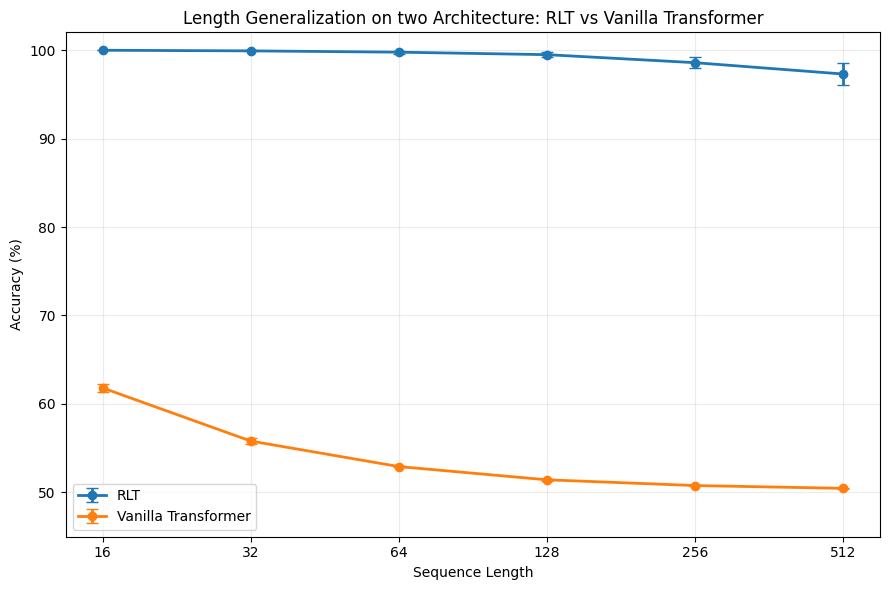

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

lengths = np.array(EVAL_LENGTHS)

# RLT
rlt_means = np.array([rlt_mean[L] for L in lengths])
rlt_stds = np.array([rlt_std[L] for L in lengths])

# Vanilla
vanilla_means = np.array([
    np.mean([
        vanilla_results[42][L],
        vanilla_results[123][L],
        vanilla_results[456][L]
    ])
    for L in lengths
])

vanilla_stds = np.array([
    np.std([
        vanilla_results[42][L],
        vanilla_results[123][L],
        vanilla_results[456][L]
    ], ddof=1)
    for L in lengths
])


plt.figure(figsize=(9, 6))

plt.errorbar(
    lengths,
    rlt_means,
    yerr=rlt_stds,
    marker="o",
    linewidth=2,
    capsize=4,
    label="RLT"
)

plt.errorbar(
    lengths,
    vanilla_means,
    yerr=vanilla_stds,
    marker="o",
    linewidth=2,
    capsize=4,
    label="Vanilla Transformer"
)

plt.xscale("log", base=2)

plt.xticks(
    lengths,
    [str(x) for x in lengths]
)

plt.xlabel("Sequence Length")
plt.ylabel("Accuracy (%)")
plt.title("Length Generalization on two Architecture: RLT vs Vanilla Transformer")

plt.ylim(45, 102)

plt.grid(True, alpha=0.25)
plt.legend()

plt.tight_layout()
plt.show()

That's still a valid controlled experiment, but for a stronger research claim we should investigate whether the Vanilla model can learn the length-16 task better with a fairer training budget.

In [ ]:
print("RLT vs Vanilla Accuracy Gap")
print("=" * 45)

for length in EVAL_LENGTHS:

    rlt = rlt_mean[length]

    vanilla_values = [
        vanilla_results[42][length],
        vanilla_results[123][length],
        vanilla_results[456][length]
    ]

    vanilla = np.mean(vanilla_values)

    gap = rlt - vanilla

    print(
        f"Length {length:3d} | "
        f"RLT {rlt:6.2f}% | "
        f"Vanilla {vanilla:6.2f}% | "
        f"Gap +{gap:5.2f} pp"
    )

RLT vs Vanilla Accuracy Gap
Length  16 | RLT  99.98% | Vanilla  61.82% | Gap +38.16 pp
Length  32 | RLT  99.90% | Vanilla  55.81% | Gap +44.09 pp
Length  64 | RLT  99.76% | Vanilla  52.93% | Gap +46.83 pp
Length 128 | RLT  99.48% | Vanilla  51.43% | Gap +48.05 pp
Length 256 | RLT  98.57% | Vanilla  50.78% | Gap +47.79 pp
Length 512 | RLT  97.29% | Vanilla  50.47% | Gap +46.82 pp


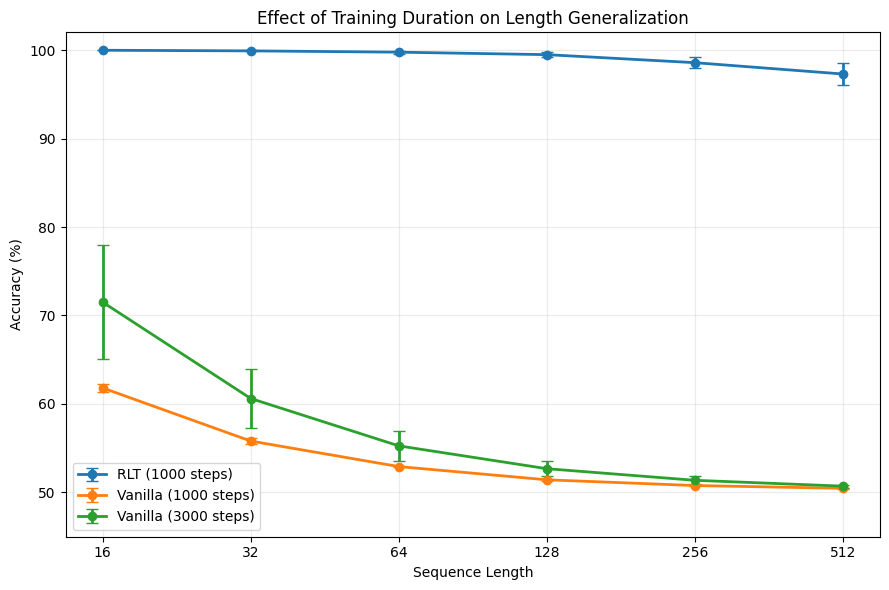

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

lengths = np.array(EVAL_LENGTHS)

# Vanilla 1000 steps
vanilla_1k_mean = np.array([
    np.mean([
        vanilla_results[42][L],
        vanilla_results[123][L],
        vanilla_results[456][L]
    ])
    for L in lengths
])

vanilla_1k_std = np.array([
    np.std([
        vanilla_results[42][L],
        vanilla_results[123][L],
        vanilla_results[456][L]
    ], ddof=1)
    for L in lengths
])

# Vanilla 3000 steps
vanilla_3k_mean = np.array([
    vanilla_long_mean[L]
    for L in lengths
])

vanilla_3k_std = np.array([
    vanilla_long_std[L]
    for L in lengths
])

# RLT
rlt_mean_values = np.array([
    rlt_mean[L]
    for L in lengths
])

rlt_std_values = np.array([
    rlt_std[L]
    for L in lengths
])


plt.figure(figsize=(9, 6))

plt.errorbar(
    lengths,
    rlt_mean_values,
    yerr=rlt_std_values,
    marker="o",
    linewidth=2,
    capsize=4,
    label="RLT (1000 steps)"
)

plt.errorbar(
    lengths,
    vanilla_1k_mean,
    yerr=vanilla_1k_std,
    marker="o",
    linewidth=2,
    capsize=4,
    label="Vanilla (1000 steps)"
)

plt.errorbar(
    lengths,
    vanilla_3k_mean,
    yerr=vanilla_3k_std,
    marker="o",
    linewidth=2,
    capsize=4,
    label="Vanilla (3000 steps)"
)

plt.xscale("log", base=2)

plt.xticks(
    lengths,
    [str(x) for x in lengths]
)

plt.xlabel("Sequence Length")
plt.ylabel("Accuracy (%)")
plt.title("Effect of Training Duration on Length Generalization")

plt.ylim(45, 102)

plt.grid(True, alpha=0.25)
plt.legend()

plt.tight_layout()
plt.show()